# MVSA-Single: Model Design
**BITS F464 Machine Learning · Multimodal Sentiment Analysis Using Text and Image Data**

This notebook covers model training and fusion. Part A explains
*which* algorithms were chosen and *why*. Part B implements them and compares them under one protocol, so
every design choice is tested rather than just argued for.

**Input:** the outputs of `mvsa_preprocessing.ipynb`. Either run this in the same Kaggle session, or attach the
saved output as a dataset (*Add Input*). The notebook finds the `preprocessed/` folder by itself.
A GPU isn't needed. The full run (4 classifier families × 6 setups × 5 seeds) takes roughly 30–45 minutes on Kaggle's CPU.
Set `QUICK = True` for a 1-seed run of a few minutes while testing.

# Part A: Design choices and justification

## A1. What the problem requires
Each design choice follows from a property of this specific problem:

| Property of the problem | Evidence | What the model design must do |
|---|---|---|
| **Small dataset**: ~3,600 training posts | 3,591 posts in the training split | Use few trainable parameters and strong regularisation. No end-to-end deep training |
| **High-dimensional, dense features**: 512 + 512 CLIP dimensions | 1,024 features for early fusion | Use algorithms that work well when features are many relative to samples (linear models with L2 penalty) |
| **Imbalanced classes**: neutral is only ~10% (376 / 3,591 training posts) | Class counts in the training split | Use class weighting, and **macro-F1** (not accuracy) to choose models |
| **Modalities often disagree**: 46.8% of posts | Text and image labels differ on these posts | Include a fusion method that can *see* disagreement and decide which modality to trust |
| **Fusion needs probabilities** | late and gated fusion combine class probabilities | Every classifier must output well-calibrated `predict_proba` |
| **Results must be explainable** | The fusion decision should be readable | Prefer models whose weights can be read, especially for the fusion step |
| **Results must be comparable and repeatable** | Scores need a mean and spread over seeds | Training must be cheap enough to repeat over 5 seeds and many configurations |

## A2. Frozen CLIP features + classical classifiers, not end-to-end deep learning
Many multimodal sentiment models train large networks end to end: object detectors, graph networks, cross-attention
stacks. We deliberately **don't**:
* **Overfitting.** CLIP ViT-B/32 has ~150M parameters. Fine-tuning it on 3,600 noisy posts would memorise the
  training set. Freezing it and training only a small classifier on top keeps the number of learned parameters
  in the thousands.
* **CLIP is designed for this.** The CLIP paper evaluates its features with a *linear probe*, a logistic
  regression on frozen embeddings, and shows it is competitive with fully fine-tuned models on many tasks.
  Its text and image vectors live in one shared space, so their cosine similarity directly measures agreement.
* **Cost and repeatability.** Features are extracted once. Every model below then trains in seconds, so the full
  comparison can be repeated over 5 seeds at low cost.

## A3. Classifier families
Four scikit-learn families are compared. They cover linear vs. non-linear, and margin-based vs. probabilistic vs. tree-based:

| Algorithm | Why it suits this problem | Its role in the comparison | Settings that address A1 |
|---|---|---|---|
| **Logistic regression** (multinomial, L2) | The standard linear probe for CLIP. Works well with many features and few samples. Outputs calibrated probabilities directly. Coefficients are readable | **Main model**, and also the gate (A5) | `class_weight="balanced"`, `C` tuned, inputs standardised |
| **Linear SVM** | Maximises the margin, which is robust in high dimensions. Often slightly stronger than LR on embeddings | Checks whether a margin-based linear model beats LR | `class_weight="balanced"`, `C` tuned. **Platt scaling** (`CalibratedClassifierCV`) adds the probabilities the SVM doesn't produce |
| **Random forest** | Non-linear, needs no scaling, gives feature importances. Handles mixed features well | **Non-linear reference**: tests whether non-linearity helps | `class_weight="balanced_subsample"`, `min_samples_leaf` tuned, 300 trees |
| **MLP** (one hidden layer, 256 units) | Learns interactions *between* text and image dimensions, which a linear model on concatenated features can't | Tests whether learned interactions help early fusion | L2 penalty `alpha` tuned, early stopping. MLP has no class weights, so minority classes are **oversampled** in training |

**Considered and rejected:**
* *k-nearest neighbours*: distances become less informative in 1,024 dimensions, and it gives poor probabilities.
* *Naive Bayes*: its independence assumption is badly violated by embedding dimensions. It suits word counts, but the TF-IDF baseline already covers text.
* *Gradient boosting* (XGBoost etc.): it fills the same "non-linear tree" role as the random forest, but it's slower on 1,000+ dense features and has more hyperparameters to tune on a 450-post validation set.
* *Kernel (RBF) SVM, deep fine-tuning*: more capacity than ~3,600 samples can support (A2).

## A4. Fusion setups
The question isn't just *which classifier* but *how the two modalities are combined*. Each setup tests one hypothesis:

| Setup | Input | Hypothesis it tests |
|---|---|---|
| **Baseline** | TF-IDF + colour histogram → LR | A simple reference that everything else is compared against |
| **Text only** | CLIP text embedding | How far text alone goes |
| **Image only** | CLIP image embedding | How much the image carries on its own |
| **Early fusion** | text ⊕ image (1,024-d) | One model sees both modalities at once |
| **Early + meta** | text ⊕ image ⊕ engineered features (Step 6a/6b of preprocessing) | Whether hand-crafted features add anything beyond CLIP |
| **Late fusion** | `w·p_text + (1−w)·p_image`, with `w` tuned on validation | A fixed trust level per modality, the same for every post |
| **Gated fusion** (proposed) | unimodal probabilities + agreement features → meta-classifier | Trust per post, based on whether the modalities agree |

## A5. Design of the gated fusion (the project's contribution)
Late fusion trusts text by the same amount `w` in every post. When text and image disagree, though, the right
answer depends on *which* modality is reliable for that post. The gate is a **stacking** meta-classifier that gets:

| Input | Meaning |
|---|---|
| `p_text` (3), `p_image` (3) | Each unimodal classifier's class probabilities |
| `clip_cosine` | How similar the text and image are in CLIP's shared space. Low means they're probably about different things |
| `js_divergence` | Jensen–Shannon divergence between `p_text` and `p_image`. 0 means the classifiers fully agree, 1 means they completely disagree |
| `conf_text`, `conf_image` | The highest probability of each classifier, i.e. how sure each one is |

Three implementation decisions matter:
1. **Out-of-fold training.** If the gate were trained on probabilities from unimodal models that had *already seen*
   those training posts, the probabilities would be over-confident and the gate would learn to trust them too much.
   So the gate's training inputs come from **5-fold cross-validation**: each post's probabilities come from models
   that never saw it. The gate is then applied at test time to models trained on the full training set.
2. **The gate is a logistic regression.** It has only 10 inputs, so a simple model is enough, and its coefficients
   show directly how much each agreement signal shifts each class.
3. The gate uses the **same classifier family** as its unimodal models, so each family is compared fairly.

## A6. Training protocol
* **Hyperparameters are tuned on the validation set only**, by macro-F1, over small grids (below). Small grids
  limit how much the selection can overfit a 450-post validation set. The test set is used once, at the end.
* **The final model is chosen by validation macro-F1**, never by test score.
* Each tuned setup is retrained with **5 seeds**, and results are reported as mean ± std. Seeds change
  the random forest, MLP initialisation, oversampling and the cross-validation folds (LR and SVM are deterministic,
  so their single-model rows show ± 0.000; their gated rows still vary through the folds). The split stays fixed
  so results line up with the saved preprocessing.
* **Reported:** accuracy, macro and per-class precision, recall and F1, accuracy per agreement group, and on the **hard-mismatch set**,
  how often the prediction matches the text label and how often it matches the image label.
* **Robustness:** the chosen model is re-tested with the image or the text replaced by its training-set mean
  embedding.
* **Significance:** a McNemar test checks whether gated vs. early fusion differ by more than chance.

# Part B: Implementation
## B0. Setup and loading

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.spatial.distance import jensenshannon
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

QUICK    = os.environ.get("MVSA_QUICK", "0") == "1"   # True: 1 seed, for a fast test run
SEEDS    = [0] if QUICK else [0, 1, 2, 3, 4]
OUT_DIR  = os.environ.get("MVSA_MODEL_OUT", "/kaggle/working/models")
LABELS   = ["negative", "neutral", "positive"]
FAMILIES = ["logreg", "linear_svm", "random_forest", "mlp"]
os.makedirs(OUT_DIR, exist_ok=True)

def find_preprocessed(roots=("/kaggle/working", "/kaggle/input")):
    """Locate the preprocessing notebook's output folder, wherever it was attached."""
    if os.environ.get("MVSA_PRE"):
        return os.environ["MVSA_PRE"]
    for r in roots:
        for dirpath, dirs, files in os.walk(r):
            if "posts_preprocessed.csv" in files and "features" in dirs:
                return dirpath
    raise FileNotFoundError("preprocessed/ not found. Run mvsa_preprocessing.ipynb first, or attach its output.")

PRE = find_preprocessed()
F = os.path.join(PRE, "features")
posts = pd.read_csv(os.path.join(PRE, "posts_preprocessed.csv"), dtype={"id": str}).set_index("id")
META_COLS = json.load(open(os.path.join(F, "meta_columns.json")))

def load(split):
    """Load one split. Row i of every array belongs to the post on line i of <split>_ids.txt."""
    ids = np.loadtxt(os.path.join(F, f"{split}_ids.txt"), dtype=str, ndmin=1)
    p = posts.loc[ids]
    return {
        "ids": ids,
        "text":  np.load(os.path.join(F, f"{split}_clip_text.npy")),
        "image": np.load(os.path.join(F, f"{split}_clip_image.npy")),
        "meta":  np.load(os.path.join(F, f"{split}_meta.npy")),
        "hist":  np.load(os.path.join(F, f"{split}_colorhist.npy")),
        "tfidf": sparse.load_npz(os.path.join(F, f"{split}_tfidf.npz")),
        "y":     p["label"].map({l: i for i, l in enumerate(LABELS)}).to_numpy(),   # NaN for 'hard'
        "group": p["mismatch_type"].to_numpy(),
        "text_label": p["text_label"].to_numpy(), "image_label": p["image_label"].to_numpy(),
    }

# "hard" holds the hard-mismatch posts: they have no single label, so they are never trained on
D = {s: load(s) for s in ["train", "val", "test", "hard"]}
for s in ["train", "val", "test"]:
    D[s]["y"] = D[s]["y"].astype(int)
ytr = D["train"]["y"]
print(f"Loaded from {PRE}")
for s, d in D.items():
    print(f"  {s:5s} {len(d['ids']):5d} posts | CLIP text {d['text'].shape[1]}-d, image {d['image'].shape[1]}-d")
print("Train class counts:", dict(zip(LABELS, np.bincount(ytr, minlength=3))))

Loaded from /kaggle/input/datasets/<kaggle-user>/mvsa-preprocessed/preprocessed
  train  3591 posts | CLIP text 512-d, image 512-d
  val     446 posts | CLIP text 512-d, image 512-d
  test    447 posts | CLIP text 512-d, image 512-d
  hard    355 posts | CLIP text 512-d, image 512-d
Train class counts: {'negative': np.int64(1078), 'neutral': np.int64(376), 'positive': np.int64(2137)}


## B1. Classifier families (A3) and their tuning grids (A6)

In [2]:
# Small grids on purpose: a large search could overfit the 446-post validation set
GRIDS = {
    "logreg":        [{"C": c} for c in (0.01, 0.1, 1.0)],
    "linear_svm":    [{"C": c} for c in (0.001, 0.01, 0.1)],
    "random_forest": [{"min_samples_leaf": m} for m in (1, 5)],
    "mlp":           [{"alpha": a} for a in (1e-3, 1e-1, 1.0)],
}

def make_clf(family, seed, C=1.0, min_samples_leaf=1, alpha=1e-3):
    """Build one untrained classifier. Scalers sit inside the pipeline, so they are fitted on training data only."""
    if family == "logreg":                 # C is the inverse of the L2 penalty: smaller C = stronger regularisation
        return make_pipeline(StandardScaler(),
                             LogisticRegression(C=C, class_weight="balanced", max_iter=5000))
    if family == "linear_svm":             # LinearSVC has no probabilities, so Platt scaling ("sigmoid") adds them
        return make_pipeline(StandardScaler(),
                             CalibratedClassifierCV(LinearSVC(C=C, class_weight="balanced", max_iter=20000),
                                                    method="sigmoid", cv=3))
    if family == "random_forest":          # a larger minimum leaf size gives simpler trees
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=min_samples_leaf, max_features="sqrt",
                                      class_weight="balanced_subsample", n_jobs=-1, random_state=seed)
    if family == "mlp":                    # alpha is the L2 penalty; early stopping also limits overfitting
        return make_pipeline(StandardScaler(),
                             MLPClassifier(hidden_layer_sizes=(256,), alpha=alpha, early_stopping=True,
                                           validation_fraction=0.15, max_iter=500, random_state=seed))
    raise ValueError(family)

def oversample(X, y, seed):
    """Repeat minority-class rows until every class is as large as the biggest (used for the MLP only)."""
    rng = np.random.default_rng(seed)
    n = np.bincount(y).max()
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), n, replace=True) for c in np.unique(y)])
    return X[idx], y[idx]

def fit(family, hp, X, y, seed):
    """Train one classifier. The MLP has no class weights, so it gets oversampled data instead."""
    if family == "mlp":
        X, y = oversample(X, y, seed)
    return make_clf(family, seed, **hp).fit(X, y)

def oof_proba(family, hp, X, y, seed, k=5):
    """Out-of-fold probabilities: each row is predicted by a model that never saw it (A5, point 1)."""
    P = np.zeros((len(y), len(LABELS)))
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=seed).split(X, y):
        P[te] = fit(family, hp, X[tr], y[tr], seed).predict_proba(X[te])
    return P

## B2. Fusion setups (A4) and the agreement gate (A5)

In [3]:
def features(d, kind):
    """Return the input matrix for one kind of model (each lambda runs only when it is selected)."""
    return {"text":       lambda: d["text"],
            "image":      lambda: d["image"],
            "early":      lambda: np.hstack([d["text"], d["image"]]),
            "early_meta": lambda: np.hstack([d["text"], d["image"], d["meta"]])}[kind]()

GATE_COLS = ([f"p_text_{l}" for l in LABELS] + [f"p_image_{l}" for l in LABELS]
             + ["clip_cosine", "js_divergence", "conf_text", "conf_image"])

def gate_inputs(p_text, p_image, d):
    """Build the gate's 10 inputs: both sets of class probabilities plus 4 agreement signals."""
    cos = (d["text"] * d["image"]).sum(axis=1, keepdims=True)   # embeddings are unit length, so this is the cosine
    js  = np.nan_to_num(jensenshannon(p_text, p_image, axis=1, base=2))[:, None]   # 0 = agree, 1 = disagree
    return np.hstack([p_text, p_image, cos, js, p_text.max(1, keepdims=True), p_image.max(1, keepdims=True)])

def make_gate(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=5000))

def macro_f1(y, P):
    """Unweighted mean of the per-class F1 scores, so the small neutral class counts as much as the others."""
    return f1_score(y, P.argmax(1), average="macro")

def build(family, cfg, seed, train=D["train"]):
    """Train every setup for one family and seed. Returns {setup: predict_proba function} and the gate."""
    hp = cfg["hp"]
    # One model per input type, trained on the full training set
    m = {k: fit(family, hp[k], features(train, k), train["y"], seed) for k in ("text", "image", "early", "early_meta")}
    # The gate trains on out-of-fold probabilities, so it never sees over-confident scores on already-seen posts
    Pt = oof_proba(family, hp["text"],  train["text"],  train["y"], seed)
    Pv = oof_proba(family, hp["image"], train["image"], train["y"], seed)
    gate = make_gate(cfg["gate_C"]).fit(gate_inputs(Pt, Pv, train), train["y"])
    w = cfg["late_w"]
    pt = lambda d: m["text"].predict_proba(d["text"])
    pv = lambda d: m["image"].predict_proba(d["image"])
    return {
        "text_only":  pt,
        "image_only": pv,
        "early":      lambda d: m["early"].predict_proba(features(d, "early")),
        "early_meta": lambda d: m["early_meta"].predict_proba(features(d, "early_meta")),
        "late":       lambda d: w * pt(d) + (1 - w) * pv(d),
        "gated":      lambda d: gate.predict_proba(gate_inputs(pt(d), pv(d), d)),
    }, gate

## B3. Hyperparameter tuning on the validation set (A6)
For each family: choose the best grid value for each input type, then the late-fusion weight `w`,
then the gate's `C`, all by **validation macro-F1** with seed 0. The test set isn't touched here.

In [4]:
def tune(family, seed=0, train=D["train"], val=D["val"]):
    hp, scores = {}, {}
    # Step 1: best grid value for each input type
    for kind in ("text", "image", "early", "early_meta"):
        best = max(GRIDS[family], key=lambda g: macro_f1(
            val["y"], fit(family, g, features(train, kind), train["y"], seed).predict_proba(features(val, kind))))
        hp[kind] = best
    # Step 2: best late-fusion weight w, from 0 (image only) to 1 (text only)
    mt = fit(family, hp["text"],  train["text"],  train["y"], seed)
    mv = fit(family, hp["image"], train["image"], train["y"], seed)
    pt, pv = mt.predict_proba(val["text"]), mv.predict_proba(val["image"])
    late_w = max(np.round(np.arange(0, 1.01, 0.1), 1), key=lambda w: macro_f1(val["y"], w * pt + (1 - w) * pv))
    # Step 3: best regularisation strength for the gate
    Gtr = gate_inputs(oof_proba(family, hp["text"], train["text"], train["y"], seed),
                      oof_proba(family, hp["image"], train["image"], train["y"], seed), train)
    Gva = gate_inputs(pt, pv, val)
    gate_C = max((0.1, 1.0, 10.0), key=lambda C: macro_f1(val["y"], make_gate(C).fit(Gtr, train["y"]).predict_proba(Gva)))
    return {"hp": hp, "late_w": float(late_w), "gate_C": gate_C}

CFG = {}
for fam in FAMILIES:
    t0 = time.time()
    CFG[fam] = tune(fam)
    print(f"{fam:14s} {time.time() - t0:6.1f}s  {CFG[fam]}")
json.dump(CFG, open(os.path.join(OUT_DIR, "tuned_hyperparameters.json"), "w"), indent=1)

logreg           49.0s  {'hp': {'text': {'C': 0.01}, 'image': {'C': 0.01}, 'early': {'C': 0.01}, 'early_meta': {'C': 0.01}}, 'late_w': 0.5, 'gate_C': 0.1}
linear_svm      131.9s  {'hp': {'text': {'C': 0.001}, 'image': {'C': 0.001}, 'early': {'C': 0.001}, 'early_meta': {'C': 0.001}}, 'late_w': 0.5, 'gate_C': 0.1}
random_forest   222.0s  {'hp': {'text': {'min_samples_leaf': 5}, 'image': {'min_samples_leaf': 5}, 'early': {'min_samples_leaf': 5}, 'early_meta': {'min_samples_leaf': 5}}, 'late_w': 0.0, 'gate_C': 0.1}
mlp              93.2s  {'hp': {'text': {'alpha': 0.1}, 'image': {'alpha': 0.1}, 'early': {'alpha': 0.001}, 'early_meta': {'alpha': 0.001}}, 'late_w': 0.5, 'gate_C': 0.1}


## B4. Training and evaluation over 5 seeds
Every setup is evaluated on **validation** (used for choosing the final model), **test** (reported), and the
**hard-mismatch** set. A hard-mismatch post has no single true label, so we report how often the model sides
with the text label and how often with the image label.

In [5]:
def evaluate(P, d):
    """Score the class probabilities P on one split, returning a dictionary of metrics."""
    pred = P.argmax(1)                                             # the predicted class is the most probable one
    if np.isnan(d["y"].astype(float)).all():                       # the 'hard' set
        lab = np.array(LABELS)[pred]
        return {"matches_text": (lab == d["text_label"]).mean(),
                "matches_image": (lab == d["image_label"]).mean(),
                "pred_neutral": (lab == "neutral").mean()}
    y = d["y"]
    out = {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
           "macro_precision": precision_score(y, pred, average="macro", zero_division=0),
           "macro_recall": recall_score(y, pred, average="macro", zero_division=0)}
    # Per-class scores: macro averages can hide one very weak class
    for name, metric in (("f1", f1_score), ("precision", precision_score), ("recall", recall_score)):
        kw = {} if name == "f1" else {"zero_division": 0}
        out.update({f"{name}_{l}": v for l, v in zip(LABELS, metric(y, pred, average=None, labels=[0, 1, 2], **kw))})
    # Accuracy per agreement group shows whether mismatched posts are harder
    for g in ("agreement", "soft_mismatch"):
        msk = d["group"] == g
        if msk.any():
            out[f"acc_{g}"] = accuracy_score(y[msk], pred[msk])
    return out

rows, PRED = [], {}
# Baseline: TF-IDF + colour histogram, logistic regression
Xb = lambda d: sparse.hstack([d["tfidf"], sparse.csr_matrix(d["hist"])]).tocsr()
base = LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000).fit(Xb(D["train"]), ytr)
for seed in SEEDS:
    r = {"family": "logreg", "setup": "baseline_tfidf_hist", "seed": seed}
    for s in ("val", "test", "hard"):
        r.update({f"{s}_{k}": v for k, v in evaluate(base.predict_proba(Xb(D[s])), D[s]).items()})
    rows.append(r)

# Every family, seed and setup is scored on validation (for choosing), test (for reporting) and hard
GATES = {}
for fam in FAMILIES:
    for seed in SEEDS:
        t0 = time.time()
        predictors, gate = build(fam, CFG[fam], seed)
        GATES[(fam, seed)] = gate
        for setup, predict in predictors.items():
            r = {"family": fam, "setup": setup, "seed": seed}
            for s in ("val", "test", "hard"):
                P = predict(D[s])
                r.update({f"{s}_{k}": v for k, v in evaluate(P, D[s]).items()})
                if s == "test":
                    PRED[(fam, setup, seed)] = P.argmax(1)
            rows.append(r)
        print(f"{fam:14s} seed {seed}: {time.time() - t0:5.1f}s")

res = pd.DataFrame(rows)
res.to_csv(os.path.join(OUT_DIR, "all_runs.csv"), index=False)

logreg         seed 0:  14.3s
logreg         seed 1:  15.2s
logreg         seed 2:  15.8s
logreg         seed 3:  14.4s
logreg         seed 4:  14.4s
linear_svm     seed 0:  25.8s
linear_svm     seed 1:  25.4s
linear_svm     seed 2:  27.4s
linear_svm     seed 3:  26.9s
linear_svm     seed 4:  28.5s
random_forest  seed 0: 137.5s
random_forest  seed 1: 136.3s
random_forest  seed 2: 138.5s
random_forest  seed 3: 135.4s
random_forest  seed 4: 135.3s
mlp            seed 0:  47.2s
mlp            seed 1:  46.2s
mlp            seed 2:  45.4s
mlp            seed 3:  48.1s
mlp            seed 4:  56.1s


## B5. Results
Test scores, mean ± std over seeds. Rows are fusion setups, columns are classifier families.
* **Accuracy** is the share of all posts predicted correctly. A majority-class guess already scores well on it here.
* **Precision** for a class: of the posts predicted as that class, the share that really are.
* **Recall** for a class: of the posts really in that class, the share the model found.
* **F1** is the harmonic mean of precision and recall, so it needs both to be high.
* **Macro** averages give each class equal weight, so the small neutral class counts as much as the others.

In [6]:
def pm(metric):
    """Format one metric as a 'mean ± std' table of setups against families."""
    g = res.groupby(["setup", "family"])[metric]
    t = (g.mean().map("{:.3f}".format) + " ± " + g.std().fillna(0).map("{:.3f}".format)).unstack()
    order = ["baseline_tfidf_hist", "text_only", "image_only", "early", "early_meta", "late", "gated"]
    return t.reindex(order)[[f for f in FAMILIES if f in t.columns]].fillna("")

print("TEST macro-F1"); print(pm("test_macro_f1").to_string())
print("\nTEST accuracy"); print(pm("test_accuracy").to_string())
print("\nTEST macro-precision"); print(pm("test_macro_precision").to_string())
print("\nTEST macro-recall"); print(pm("test_macro_recall").to_string())

TEST macro-F1
family                      logreg     linear_svm  random_forest            mlp
setup                                                                          
baseline_tfidf_hist  0.504 ± 0.000                                             
text_only            0.518 ± 0.000  0.559 ± 0.000  0.561 ± 0.008  0.571 ± 0.014
image_only           0.561 ± 0.000  0.544 ± 0.000  0.541 ± 0.009  0.595 ± 0.012
early                0.609 ± 0.000  0.616 ± 0.000  0.569 ± 0.013  0.640 ± 0.010
early_meta           0.620 ± 0.000  0.615 ± 0.000  0.631 ± 0.009  0.655 ± 0.021
late                 0.603 ± 0.000  0.574 ± 0.000  0.541 ± 0.009  0.632 ± 0.012
gated                0.596 ± 0.004  0.626 ± 0.005  0.604 ± 0.009  0.603 ± 0.014

TEST accuracy
family                      logreg     linear_svm  random_forest            mlp
setup                                                                          
baseline_tfidf_hist  0.622 ± 0.000                                             
text_only  

### Choosing the final model (by validation, not test)

In [7]:
# Model selection: the highest mean validation macro-F1 wins. Test columns are only reported, never used to choose.
summary = res.groupby(["family", "setup"]).mean(numeric_only=True).drop(columns="seed")
best_fam, best_setup = summary["val_macro_f1"].idxmax()
print(f"Chosen by validation macro-F1: {best_fam} + {best_setup}\n")
cols = ["val_macro_f1", "test_macro_f1", "test_accuracy", "test_f1_negative", "test_f1_neutral", "test_f1_positive",
        "test_acc_agreement", "test_acc_soft_mismatch", "hard_matches_text", "hard_matches_image", "hard_pred_neutral"]
top = summary.sort_values("val_macro_f1", ascending=False)[[c for c in cols if c in summary]].head(8)
print(top.round(3).to_string())
summary.round(4).to_csv(os.path.join(OUT_DIR, "summary_mean_over_seeds.csv"))

Chosen by validation macro-F1: logreg + late

                          val_macro_f1  test_macro_f1  test_accuracy  test_f1_negative  test_f1_neutral  test_f1_positive  test_acc_agreement  test_acc_soft_mismatch  hard_matches_text  hard_matches_image  hard_pred_neutral
family        setup                                                                                                                                                                                                            
logreg        late               0.619          0.603          0.696             0.676            0.352             0.780               0.759                   0.613              0.411               0.510              0.079
mlp           early_meta         0.613          0.655          0.757             0.710            0.421             0.834               0.811                   0.688              0.459               0.506              0.035
linear_svm    gated              0.613          0.626     

### Precision, recall and F1 per class for the chosen model
The first table averages over seeds. The second is scikit-learn's full report for seed 0, which adds each class's
number of test posts (`support`).

In [8]:
per_class = pd.DataFrame({m: [summary.loc[(best_fam, best_setup), f"test_{m}_{l}"] for l in LABELS]
                          for m in ("precision", "recall", "f1")}, index=LABELS)
print(f"{best_fam} + {best_setup}, mean over seeds:")
print(per_class.round(3).to_string())
per_class.round(4).to_csv(os.path.join(OUT_DIR, "per_class_metrics.csv"))
print("\nSeed 0:")
print(classification_report(D["test"]["y"], PRED[(best_fam, best_setup, 0)], labels=[0, 1, 2], target_names=LABELS, digits=3))

logreg + late, mean over seeds:
          precision  recall     f1
negative      0.653   0.701  0.676
neutral       0.275   0.487  0.352
positive      0.846   0.723  0.780

Seed 0:
              precision    recall  f1-score   support

    negative      0.653     0.701     0.676       134
     neutral      0.275     0.487     0.352        39
    positive      0.846     0.723     0.780       274

    accuracy                          0.696       447
   macro avg      0.591     0.637     0.603       447
weighted avg      0.738     0.696     0.711       447



### Per-group view for the chosen family
The key question: does the gate help on mismatched posts *without* hurting agreeing posts?

In [9]:
grp_cols = [c for c in ["test_acc_agreement", "test_acc_soft_mismatch", "hard_matches_text", "hard_matches_image"] if c in summary]
print(summary.loc[best_fam][grp_cols].reindex(["text_only", "image_only", "early", "late", "gated"]).round(3).to_string())

            test_acc_agreement  test_acc_soft_mismatch  hard_matches_text  hard_matches_image
setup                                                                                        
text_only                0.696                   0.505              0.597               0.273
image_only               0.684                   0.588              0.248               0.651
early                    0.779                   0.639              0.397               0.513
late                     0.759                   0.613              0.411               0.510
gated                    0.755                   0.569              0.376               0.494


## B6. Is gated fusion significantly different from early fusion? (McNemar, seed 0)
McNemar's test only looks at posts where the two models *disagree*: `b` = early right and gated wrong,
`c` = gated right and early wrong. If the models were equally good, `b` and `c` would be about equal.

In [10]:
yte = D["test"]["y"]
for fam in FAMILIES:
    # b and c count the posts that only one of the two models got right
    e_ok, g_ok = PRED[(fam, "early", 0)] == yte, PRED[(fam, "gated", 0)] == yte
    b, c = int((e_ok & ~g_ok).sum()), int((~e_ok & g_ok).sum())
    p = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0     # exact form of McNemar's test
    print(f"{fam:14s} early-only correct={b:3d}  gated-only correct={c:3d}  p={p:.3f}  "
          f"{'significant' if p < 0.05 else 'not significant'} at 5%")

logreg         early-only correct= 38  gated-only correct= 19  p=0.016  significant at 5%
linear_svm     early-only correct= 57  gated-only correct= 31  p=0.007  significant at 5%
random_forest  early-only correct= 78  gated-only correct= 60  p=0.148  not significant at 5%
mlp            early-only correct= 45  gated-only correct= 27  p=0.044  significant at 5%


## B7. Robustness: what if one modality is missing?
The image (or text) embedding of every test post is replaced by the **training-set mean** embedding, so the model
receives an average input for that modality.
**Read macro-F1, not just accuracy.** The mean embedding isn't truly neutral: the unimodal models predict "positive"
for every post when given it, so masking pushes predictions towards the majority class and can flatter accuracy.
`pos_*` shows the share of posts predicted positive, which makes this visible.

In [11]:
def masked(d, modality):
    """Copy a split with one modality replaced by its training-set mean embedding, to simulate it being missing."""
    m = dict(d)
    m[modality] = np.repeat(D["train"][modality].mean(0, keepdims=True), len(d["ids"]), axis=0)
    return m

predictors, _ = build(best_fam, CFG[best_fam], 0)
rob = []
for setup in ["early", "late", "gated"]:
    row = {"setup": setup}
    for name, d in [("full", D["test"]), ("no_image", masked(D["test"], "image")), ("no_text", masked(D["test"], "text"))]:
        P = predictors[setup](d)
        row[f"acc_{name}"] = accuracy_score(D["test"]["y"], P.argmax(1))
        row[f"f1_{name}"]  = macro_f1(D["test"]["y"], P)
        row[f"pos_{name}"] = (P.argmax(1) == LABELS.index("positive")).mean()
    row["f1_drop_no_image"] = row["f1_full"] - row["f1_no_image"]
    row["f1_drop_no_text"]  = row["f1_full"] - row["f1_no_text"]
    rob.append(row)
rob = pd.DataFrame(rob).set_index("setup")
print(f"Family: {best_fam}\n" + rob.round(3).to_string())
rob.to_csv(os.path.join(OUT_DIR, "robustness_missing_modality.csv"))

Family: logreg
       acc_full  f1_full  pos_full  acc_no_image  f1_no_image  pos_no_image  acc_no_text  f1_no_text  pos_no_text  f1_drop_no_image  f1_drop_no_text
setup                                                                                                                                               
early     0.718    0.609     0.553         0.653        0.493         0.653        0.698       0.590        0.613             0.116            0.020
late      0.696    0.603     0.523         0.691        0.565         0.626        0.711       0.610        0.606             0.038           -0.008
gated     0.676    0.602     0.481         0.682        0.542         0.606        0.671       0.586        0.528             0.060            0.016


## B8. What the gate learned
The gate is a standardised logistic regression, so each coefficient means: *one standard deviation more of this
input changes the log-odds of the class by this much*. Look at the rows `js_divergence` and `clip_cosine` in particular:
they show how disagreement moves predictions, for example towards neutral, or towards trusting the text.

In [12]:
gate = GATES[(best_fam, 0)]
coef = pd.DataFrame(gate[-1].coef_.T, index=GATE_COLS, columns=gate[-1].classes_)
coef.columns = [LABELS[c] for c in coef.columns]
print(f"Gate coefficients ({best_fam}, seed 0):")
print(coef.round(3).to_string())
coef.to_csv(os.path.join(OUT_DIR, "gate_coefficients.csv"))

# Rows are the true classes and columns the predictions, so off-diagonal cells show which classes get confused
cm = confusion_matrix(yte, PRED[(best_fam, best_setup, 0)], labels=[0, 1, 2])
print(f"\nTest confusion matrix, {best_fam} + {best_setup} (rows = true, cols = predicted):")
print(pd.DataFrame(cm, index=LABELS, columns=LABELS).to_string())

json.dump({"chosen_family": best_fam, "chosen_setup": best_setup, "seeds": SEEDS, "config": CFG[best_fam]},
          open(os.path.join(OUT_DIR, "chosen_model.json"), "w"), indent=1)
print("\nSaved to", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

Gate coefficients (logreg, seed 0):
                  negative  neutral  positive
p_text_negative      0.347   -0.100    -0.247
p_text_neutral      -0.114    0.221    -0.107
p_text_positive     -0.240   -0.073     0.314
p_image_negative     0.309   -0.067    -0.242
p_image_neutral     -0.078    0.318    -0.240
p_image_positive    -0.220   -0.186     0.406
clip_cosine         -0.038    0.106    -0.068
js_divergence       -0.022    0.007     0.015
conf_text           -0.082    0.028     0.054
conf_image           0.026   -0.104     0.078

Test confusion matrix, logreg + late (rows = true, cols = predicted):
          negative  neutral  positive
negative        94       14        26
neutral         10       19        10
positive        40       36       198

Saved to /kaggle/working/models : ['all_runs.csv', 'chosen_model.json', 'gate_coefficients.csv', 'per_class_metrics.csv', 'robustness_missing_modality.csv', 'summary_mean_over_seeds.csv', 'tuned_hyperparameters.json']


## B9. Bias-variance trade-off and regularisation
Logistic regression's `C` is the inverse of the L2 penalty: small `C` means strong regularisation and a simpler model.
We sweep `C` far beyond the tuning grid and compare **training** and **validation** macro-F1 (the test set isn't used):
* **Low scores on both** at small `C` suggest high bias (underfitting).
* **A widening gap** between the two at large `C` suggests high variance (overfitting).
* **The best `C`** is where validation macro-F1 peaks, which is what model selection looks for.

          early_train  early_val  late_train  late_val
C                                                     
0.0001          0.709      0.609       0.683     0.601
0.0010          0.806      0.598       0.758     0.627
0.0100          0.893      0.559       0.815     0.619
0.1000          0.962      0.532       0.833     0.593
1.0000          0.990      0.529       0.839     0.575
10.0000         0.991      0.532       0.840     0.583
100.0000        0.991      0.528       0.841     0.576


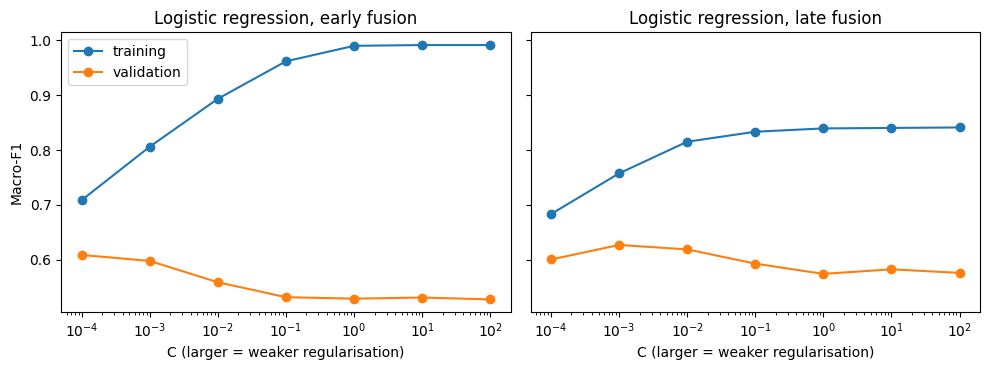

In [13]:
import matplotlib.pyplot as plt

# Wider than the tuning grid, so that both ends of the bias-variance curve can show. Used for this plot only.
C_SWEEP = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
trn, vld = D["train"], D["val"]
curve = []
for C in C_SWEEP:
    mods = {k: fit("logreg", {"C": C}, features(trn, k), trn["y"], 0) for k in ("text", "image", "early")}
    w = CFG["logreg"]["late_w"]
    late = lambda d: w * mods["text"].predict_proba(d["text"]) + (1 - w) * mods["image"].predict_proba(d["image"])
    curve.append({"C": C,
                  "early_train": macro_f1(trn["y"], mods["early"].predict_proba(features(trn, "early"))),
                  "early_val":   macro_f1(vld["y"], mods["early"].predict_proba(features(vld, "early"))),
                  "late_train":  macro_f1(trn["y"], late(trn)),
                  "late_val":    macro_f1(vld["y"], late(vld))})
curve = pd.DataFrame(curve).set_index("C")
print(curve.round(3).to_string())
curve.to_csv(os.path.join(OUT_DIR, "bias_variance_curve.csv"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, name in zip(axes, ["early", "late"]):
    ax.plot(curve.index, curve[f"{name}_train"], marker="o", label="training")
    ax.plot(curve.index, curve[f"{name}_val"], marker="o", label="validation")
    ax.set_xscale("log"); ax.set_xlabel("C (larger = weaker regularisation)"); ax.set_title(f"Logistic regression, {name} fusion")
axes[0].set_ylabel("Macro-F1"); axes[0].legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "bias_variance_curve.png"), dpi=150); plt.show()

### Tuned hyperparameters per family and input

In [14]:
print(json.dumps(CFG, indent=1))

{
 "logreg": {
  "hp": {
   "text": {
    "C": 0.01
   },
   "image": {
    "C": 0.01
   },
   "early": {
    "C": 0.01
   },
   "early_meta": {
    "C": 0.01
   }
  },
  "late_w": 0.5,
  "gate_C": 0.1
 },
 "linear_svm": {
  "hp": {
   "text": {
    "C": 0.001
   },
   "image": {
    "C": 0.001
   },
   "early": {
    "C": 0.001
   },
   "early_meta": {
    "C": 0.001
   }
  },
  "late_w": 0.5,
  "gate_C": 0.1
 },
 "random_forest": {
  "hp": {
   "text": {
    "min_samples_leaf": 5
   },
   "image": {
    "min_samples_leaf": 5
   },
   "early": {
    "min_samples_leaf": 5
   },
   "early_meta": {
    "min_samples_leaf": 5
   }
  },
  "late_w": 0.0,
  "gate_C": 0.1
 },
 "mlp": {
  "hp": {
   "text": {
    "alpha": 0.1
   },
   "image": {
    "alpha": 0.1
   },
   "early": {
    "alpha": 0.001
   },
   "early_meta": {
    "alpha": 0.001
   }
  },
  "late_w": 0.5,
  "gate_C": 0.1
 }
}


## Where to find each result
* **Main results:** the B5 macro-F1, accuracy, macro-precision and macro-recall tables.
* **Per-class results:** the B5 precision, recall and F1 tables for the chosen model.
* **Per-group results:** the B5 per-group view.
* **Significance:** the B6 McNemar results.
* **Robustness:** the B7 table, noting the mean-embedding bias towards "positive".
* **Interpretation:** the B8 gate coefficients.
* **Bias-variance and regularisation:** the B9 curve and table, plus the tuned hyperparameters.